<a href="https://colab.research.google.com/github/altupas/DSC1109/blob/main/KNN_dimensionality_ACTIVITY.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Machine Learning: Activity 1
## K Nearest Neighbours and the Curse of Dimensionality

**Name:** Aldrin A. Tupas
**Section:** 1
**Date:** 10/19/26

---

### How this activity works

Cells marked **`# TODO`** are yours to complete. Everything else is given;
run it and read it, but you do not need to change it.

Every blank is answerable from the lecture slides. The slide is named next
to each one, like this: *(Slide: KNN)*. If you cannot answer a blank from
the slides, say so in your write-up, that is useful feedback.

Several cells say **CHECK**. They run `assert` statements against your
answer. If a CHECK cell runs without printing an error, your code is
correct and you can move on.

### What you need from the lecture

1. The KNN voting rule and the Euclidean metric *(Slide: K Nearest Neighbours)*
2. The MAP rule: predict the most probable label *(Slide: The posterior)*
3. Edge length $\ell = f^{1/D}$ *(Slide: Where KNN breaks)*
4. Training error is not generalization *(Slide: Why we cannot score on the training set)*
5. What cross-validation is for *(Slide: Cross-Validation)*


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neighbors import KNeighborsClassifier

RNG_SEED = 143
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["figure.dpi"] = 110
print("Setup complete.")

Setup complete.


---
## Part 0. The dataset

Two Gaussian blobs in 2-D, one per class. We can bolt on extra
**pure-noise** features later. The signal never changes; only the number
of useless dimensions grows. That is the point of the whole activity.

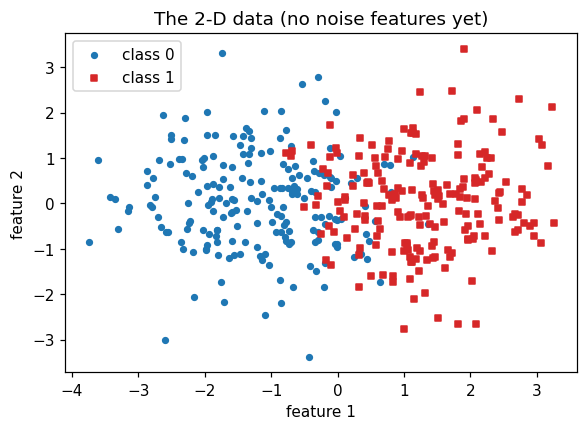

In [ ]:
def make_data(n=400, n_noise=0, seed=0):
    """Two Gaussian blobs in 2-D, plus `n_noise` features of pure noise."""
    rng = np.random.default_rng(seed)
    h = n // 2
    X = np.vstack([rng.normal([-1.2, 0], 1.0, (h, 2)),
                   rng.normal([+1.2, 0], 1.0, (n - h, 2))])
    y = np.r_[np.zeros(h, dtype=int), np.ones(n - h, dtype=int)]
    if n_noise:
        X = np.hstack([X, rng.normal(size=(n, n_noise))])
    p = rng.permutation(n)
    return X[p], y[p]


X2, y2 = make_data(seed=RNG_SEED)
plt.scatter(*X2[y2 == 0].T, s=14, c="tab:blue", label="class 0")
plt.scatter(*X2[y2 == 1].T, s=14, c="tab:red", marker="s", label="class 1")
plt.legend(); plt.title("The 2-D data (no noise features yet)")
plt.xlabel("feature 1"); plt.ylabel("feature 2"); plt.show()

---
## Part 1. Build KNN from the lecture formula

From the slide:

$$p(y = c \mid \mathbf{x}, \mathcal{D}, K)
  = \frac{1}{K} \sum_{i \in N_K(\mathbf{x}, \mathcal{D})} \mathbb{I}(y_i = c)$$

You will implement this in three small pieces.

### TODO 1: the distance function

*(Slide: KNN, "Euclidean metric often used")*

Return the Euclidean distance from one query point `x` to **every** row of
`X_train`. The result is a 1-D array with one entry per training point.

Reminder: $d(\mathbf{x}, \mathbf{x}_i) = \sqrt{\sum_j (x_j - x_{ij})^2}$.

In [ ]:
def distances_to_training_set(x, X_train):
    """Euclidean distance from x to every row of X_train.

    x       : shape (n_features,)
    X_train : shape (n_samples, n_features)
    returns : shape (n_samples,)
    """
    return np.sqrt(((x - X_train) ** 2).sum(axis=1))

In [ ]:
# CHECK 1
_Xt = np.array([[0.0, 0.0], [3.0, 4.0], [1.0, 0.0]])
_d = distances_to_training_set(np.array([0.0, 0.0]), _Xt)
assert _d.shape == (3,), f"expected shape (3,), got {_d.shape}"
assert np.allclose(_d, [0.0, 5.0, 1.0]), f"expected [0, 5, 1], got {_d}"
print("CHECK 1 passed.")

CHECK 1 passed.


### TODO 2: the vote

*(Slide: K Nearest Neighbours)*

Fill in the two blanks so the function returns the vector
$\bigl[p(y=0 \mid \cdot), \; p(y=1 \mid \cdot)\bigr]$.

The counts must sum to $K$ before you divide, so the returned
probabilities sum to 1.

In [ ]:
def knn_predict_proba(x, X_train, y_train, K, n_classes=2):
    """Return p(y = c | x, D, K) for every class c, as an array."""
    d = distances_to_training_set(x, X_train)

    # TODO 2a: indices of the K training points with the SMALLEST distance.
    neighbour_idx = np.argsort(d)[:K]

    counts = np.zeros(n_classes)
    for i in neighbour_idx:
        # TODO 2b: add one vote for the label of training point i
        counts[y_train[i]] += 1

    return counts / K

### TODO 3: the decision

*(Slide: The posterior, and the decision it implies)*

The slide says the predicted label is the **mode** of the posterior, the
MAP estimate:

$$\hat{y} = \arg\max_{c} \; p(y = c \mid \mathbf{x}, \mathcal{D})$$

Turn the probability vector into a single predicted label.

In [ ]:
def knn_predict(X_query, X_train, y_train, K):
    """Predict a label for every row of X_query."""
    preds = []
    for x in X_query:
        proba = knn_predict_proba(x, X_train, y_train, K)
        # TODO: apply the MAP rule to `proba`
        label = np.argmax(proba)
        preds.append(label)
    return np.array(preds)

In [ ]:
# CHECK 2 and 3: your KNN must agree with scikit-learn's
Xtr, Xte, ytr, yte = train_test_split(X2, y2, test_size=0.3,
                                      random_state=RNG_SEED)
for _K in [1, 3, 7]:
    mine = knn_predict(Xte, Xtr, ytr, _K)
    theirs = KNeighborsClassifier(n_neighbors=_K).fit(Xtr, ytr).predict(Xte)
    agree = (mine == theirs).mean()
    assert agree > 0.98, f"K={_K}: only {agree:.1%} agreement with sklearn"
    print(f"K={_K}: {agree:.1%} agreement with scikit-learn")
print("CHECKS 2 and 3 passed.")

K=1: 100.0% agreement with scikit-learn
K=3: 100.0% agreement with scikit-learn
K=7: 100.0% agreement with scikit-learn
CHECKS 2 and 3 passed.


---
## Part 2. The decision boundary

*(Slide: What KNN carves out)*

With $K = 1$ the decision regions are a Voronoi tessellation. Larger $K$
averages over more neighbours. Run the cell and watch what changes.

In [ ]:
def plot_boundary(K, X_train, y_train, ax):
    pad, step = 1.0, 0.08
    x_min, x_max = X_train[:, 0].min() - pad, X_train[:, 0].max() + pad
    y_min, y_max = X_train[:, 1].min() - pad, X_train[:, 1].max() + pad
    xx, yy = np.meshgrid(np.arange(x_min, x_max, step),
                         np.arange(y_min, y_max, step))
    grid = np.c_[xx.ravel(), yy.ravel()]
    zz = knn_predict(grid, X_train, y_train, K).reshape(xx.shape)
    ax.contourf(xx, yy, zz, alpha=0.25, cmap="coolwarm", levels=1)
    ax.scatter(*X_train[y_train == 0].T, s=10, c="tab:blue")
    ax.scatter(*X_train[y_train == 1].T, s=10, c="tab:red", marker="s")
    ax.set_title(f"K = {K}"); ax.set_xticks([]); ax.set_yticks([])


X_small, y_small = make_data(n=150, seed=RNG_SEED)
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
for ax, K in zip(axes, [1, 3, 15, 51]):
    plot_boundary(K, X_small, y_small, ax)
plt.tight_layout(); plt.show()

### Q1. Describe the boundary *(Slide: What KNN carves out)*

Looking at the four panels, answer in one or two sentences each:

**(a)** Which value of $K$ produces the most jagged boundary, and what is
the slide's word for what a jagged boundary is following?

> *the k=1 produces the most jagged boundary as the slide term for following the saple noise closely is overfitting.*

**(b)** What does the boundary do as $K$ grows to 51, and what is the risk?

> *as k grows to 51 the boundary becomes extremely smooth and eventually turns into a simple linear seperator or majority dominance, as the risk is underfitting where the model fails to capture local pattern in the data.*

---
## Part 3. Training error is not generalization

*(Slide: Why we cannot score on the training set)*

The slide makes a specific claim about 1-NN scored on its own training
data. Test it.

### TODO 4: score 1-NN on its own training set

Use **your** `knn_predict`. Predict on `Xtr` itself, then compute accuracy
against `ytr`.

In [ ]:
# TODO: predict on the TRAINING set and compute training accuracy
train_pred = knn_predict(Xtr, Xtr, ytr, K=1)          # hint: knn_predict(Xtr, Xtr, ytr, K=1)
train_acc = (train_pred == ytr).mean()           # hint: compare to ytr and take the mean

test_pred = knn_predict(Xte, Xtr, ytr, K=1)
test_acc = (test_pred == yte).mean()

print(f"1-NN training accuracy: {train_acc:.3f}")
print(f"1-NN test accuracy:     {test_acc:.3f}")

1-NN training accuracy: 1.000
1-NN test accuracy:     0.900


In [ ]:
# CHECK 4
assert train_acc == 1.0, f"expected exactly 1.000, got {train_acc}"
print("CHECK 4 passed: training accuracy is exactly 1.000.")

CHECK 4 passed: training accuracy is exactly 1.000.


### Q2. Explain the result *(Slide: Why we cannot score on the training set)*

**(a)** Why is the training accuracy *exactly* 1.000, for any dataset?

> *it exactly as for 1-NN, every training point nearest neighbor is itself (with a distance of 0), so it always predict its own label giving a training accuracy of exactly 1.0*

**(b)** The slide says a model can fit the training set perfectly and
still be useless. Which of the two numbers you printed tells you
something about new inputs, and why?

> *the test accuracy tells you about new inputs because it evaluates performace on completely unseen data where as training accuracy only measures memorization*

---
## Part 4. The curse of dimensionality

*(Slide: Where KNN breaks)*

The slide gives the edge length of a cube-shaped neighbourhood that
captures a fraction $f$ of uniformly spread data in $D$ dimensions:

$$\ell = f^{1/D}$$

### TODO 5: reproduce the table from the slide

Implement $\ell = f^{1/D}$ and print the row for $f = 0.1$.

In [ ]:
def edge_length(f, D):
    """Edge length of a cube-shaped neighbourhood capturing fraction f."""
    # TODO: one line, straight from the slide
    return f ** (1 / D)


for D in [1, 2, 5, 10, 50, 100]:
    print(f"D = {D:3d}   edge length = {edge_length(0.1, D):.3f}")

D =   1   edge length = 0.100
D =   2   edge length = 0.316
D =   5   edge length = 0.631
D =  10   edge length = 0.794
D =  50   edge length = 0.955
D = 100   edge length = 0.977


In [ ]:
# CHECK 5: these are the numbers on the slide
assert abs(edge_length(0.1, 1) - 0.100) < 1e-3
assert abs(edge_length(0.1, 10) - 0.794) < 1e-3
assert abs(edge_length(0.1, 100) - 0.977) < 1e-3
print("CHECK 5 passed: your table matches the slide.")

CHECK 5 passed: your table matches the slide.


### TODO 6: measure the damage

Now the experiment. For each setting we add pure-noise features and
measure test accuracy. The signal in features 1 and 2 **never changes**,
so any drop is caused by the extra dimensions alone.

Fill in the two lines that train and score the classifier. Use
`KNeighborsClassifier(n_neighbors=5)` here, your own implementation is
correct but slower.

In [ ]:
DIMS = [2, 5, 10, 20, 50, 100, 200, 500]
N_REPEATS = 10
mean_acc = []

for D in DIMS:
    accs = []
    for s in range(N_REPEATS):
        X, y = make_data(n=400, n_noise=D - 2, seed=s)
        Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.3, random_state=s)

        # TODO 6a: fit a 5-NN classifier on (Xa, ya)
        clf = KNeighborsClassifier(n_neighbors=5).fit(Xa, ya)
        # TODO 6b: append its accuracy on (Xb, yb)
        accs.append(clf.score(Xb, yb))

    mean_acc.append(np.mean(accs))
    print(f"D = {D:3d}   test accuracy = {mean_acc[-1]:.3f}")

D =   2   test accuracy = 0.879
D =   5   test accuracy = 0.863
D =  10   test accuracy = 0.830
D =  20   test accuracy = 0.822
D =  50   test accuracy = 0.758
D = 100   test accuracy = 0.729
D = 200   test accuracy = 0.673
D = 500   test accuracy = 0.579


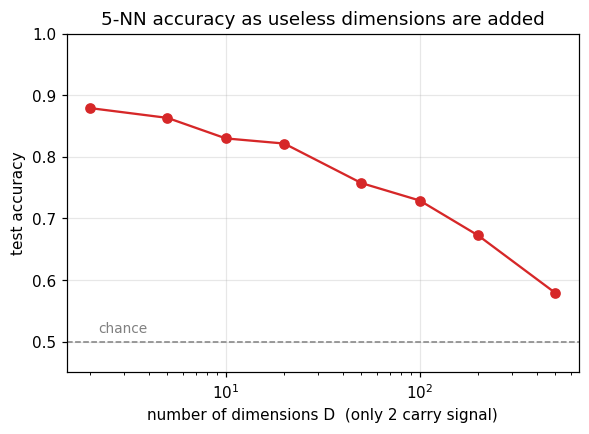

In [ ]:
plt.semilogx(DIMS, mean_acc, "o-", color="tab:red")
plt.axhline(0.5, ls="--", c="gray", lw=1)
plt.text(2.2, 0.515, "chance", color="gray", fontsize=9)
plt.xlabel("number of dimensions D  (only 2 carry signal)")
plt.ylabel("test accuracy")
plt.title("5-NN accuracy as useless dimensions are added")
plt.ylim(0.45, 1.0); plt.grid(alpha=0.3); plt.show()

### Why it happens

The cell below is given. It measures, for each $D$, the ratio

$$\text{ratio} = \frac{\text{distance to the nearest training point}}
                      {\text{distance to the farthest training point}}$$

averaged over many query points. Read the output before answering Q3.

D =   2   nearest / farthest = 0.029
D =   5   nearest / farthest = 0.152
D =  10   nearest / farthest = 0.292
D =  20   nearest / farthest = 0.434
D =  50   nearest / farthest = 0.607
D = 100   nearest / farthest = 0.704
D = 200   nearest / farthest = 0.783
D = 500   nearest / farthest = 0.854


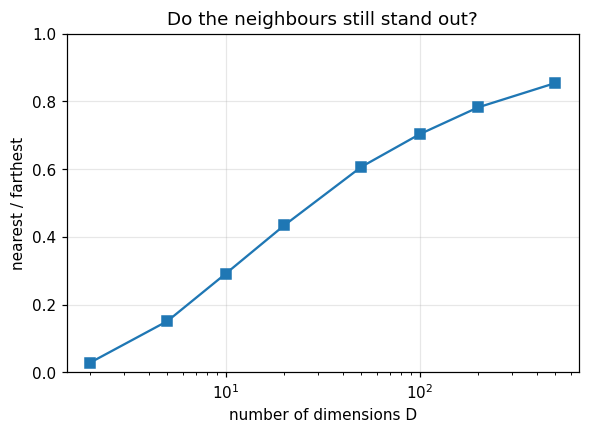

In [ ]:
ratios = []
for D in DIMS:
    r = []
    for s in range(5):
        X, y = make_data(n=400, n_noise=D - 2, seed=s)
        Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.3, random_state=s)
        d = np.sqrt(((Xa[None, :, :] - Xb[:30, None, :]) ** 2).sum(-1))
        r.append((d.min(axis=1) / d.max(axis=1)).mean())
    ratios.append(np.mean(r))
    print(f"D = {D:3d}   nearest / farthest = {ratios[-1]:.3f}")

plt.semilogx(DIMS, ratios, "s-", color="tab:blue")
plt.xlabel("number of dimensions D"); plt.ylabel("nearest / farthest")
plt.title("Do the neighbours still stand out?")
plt.ylim(0, 1); plt.grid(alpha=0.3); plt.show()

### Q3. Connect the three results *(Slide: Where KNN breaks)*

**(a)** What value does the nearest/farthest ratio approach as $D$ grows?
State in words what that means about the nearest neighbour compared to
the farthest point.

> *as the D grow, the nereast ratio approach 1.0. this means that the distance to the nearest neighbor becomes almost indistinguishable from the distance to the farthest neighbor.*

**(b)** The slide says that at $D = 100$ a "local" neighbourhood spans
$98\%$ of every feature. Using your table from TODO 5 and the ratio you
just measured, explain in two or three sentences why the accuracy curve
falls even though the signal in features 1 and 2 never changed.

> *the dimensionality increases, local neighborhoods must expand to span almost the entire range of every features to capture enough points. bacause all points become equally distant so the nearest neighbors no longer share a meaningful class signal, cauisng the accuracy to degrade to random chance (0.5)*

---
## Part 5. Choosing K honestly

*(Slide: Cross-Validation)*

$K$ is a hyperparameter. The slide says cross-validation's main job is
choosing hyperparameters **without touching the test set**.

### TODO 7: pick K with 5-fold cross-validation

Use `cross_val_score(estimator, X, y, cv=5)`, which returns one score per
fold. Score each candidate $K$ on the **training** data only, then
evaluate the winner once on the test data.

In [ ]:
X, y = make_data(n=400, n_noise=8, seed=RNG_SEED)
Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.3, random_state=RNG_SEED)

candidate_K = [1, 3, 5, 9, 15, 25, 51]
cv_means = []

for K in candidate_K:
    # TODO 7a: 5-fold CV scores for this K, on the TRAINING data only
    scores = cross_val_score(KNeighborsClassifier(n_neighbors=K), Xa, ya, cv=5)
    cv_means.append(np.mean(scores))
    print(f"K = {K:3d}   CV accuracy = {cv_means[-1]:.3f}")

# TODO 7b: the K with the highest mean CV accuracy
best_K = candidate_K[np.argmax(cv_means)]
print(f"\nBest K by cross-validation: {best_K}")

final = KNeighborsClassifier(n_neighbors=best_K).fit(Xa, ya)
print(f"Held-out test accuracy with K={best_K}: {final.score(Xb, yb):.3f}")

K =   1   CV accuracy = 0.807
K =   3   CV accuracy = 0.854
K =   5   CV accuracy = 0.846
K =   9   CV accuracy = 0.843
K =  15   CV accuracy = 0.864
K =  25   CV accuracy = 0.875
K =  51   CV accuracy = 0.893

Best K by cross-validation: 51
Held-out test accuracy with K=51: 0.908


In [ ]:
# CHECK 7
assert best_K in candidate_K, "best_K must come from candidate_K"
assert len(cv_means) == len(candidate_K), "one CV score per candidate K"
print(f"CHECK 7 passed: selected K = {best_K}.")

CHECK 7 passed: selected K = 51.


### Q4. Why not just use the test set? *(Slide: Cross-Validation)*

Suppose you skipped cross-validation, tried all seven values of $K$
directly on `Xb`, and reported the best score you saw.

**(a)** What is wrong with the number you would report?

> *if i omptimize K directly on the test set (Xb), it will leak test information into the model selection process. the reported accuracy will be overly optimistic and biased, failing to reflect true generalization.*

**(b)** The slide gives cross-validation's main job in one phrase. State
it, and explain how the cell above follows it.

> *Cross validation main job is choosing hyperparameters without touching the test set. The code follows this by evaluating all candidate K values using 5 fold CV exclusively on the training subset (Xa, ya) keeping Xb completely sealed until final evaluation.*

---
## Part 6. Wrap-up

### Q5. Inductive bias *(Slide: Inductive bias)*

The slide states the assumption KNN makes in one word, plus a short
gloss.

**(a)** What is that assumption?

> *The assumption KNN makes is locality where a point close to each other in feature space tend to share the same label.*

**(b)** Using your own results from Part 4, explain in two or three
sentences why that assumption fails when $D = 500$.

> *When the D = 500 the curse of the dimensionality makes all point roughly equal from one another. Consequently, closeness loses it meaning, rendering the assumption is invalid.*

### Q6. Open question

You are handed the $D = 500$ dataset and told to make KNN work on it.
Propose **one** change and say, in one sentence, which of your measured
quantities you would expect it to improve.

> *Applying the dimensionality reduction technique to filter out the useless 498 noise feature to keep the informative dimensions.*

*(This one is not answerable directly from the slides. An honest "I am
not sure, but here is my reasoning" earns full credit.)*

---

### Submission

1. `Runtime` then `Run all` to confirm every CHECK passes.
2. `File` then `Download` then `Download .ipynb`.
3. Submit the `.ipynb` with all outputs visible and all questions answered.